# 01 · Data preparation & reference implementation

**AI in Operations, Session II: AI Applications in Reorder Point & Inventory Management (Exercise)**

What this notebook does:

1. **Cleans** the Kaggle *Store Sales – Time Series Forecasting* (Corporación Favorita) files.
2. **Builds** a Quito holiday/event calendar and the external factors (oil price, payday).
3. **Exports** a small subset (`data/derived/favorita_subset.json`, 9 store × family series). The dashboard loads this file in the browser.
4. Acts as an **independent reference implementation** (NumPy/SciPy) of the feature set, seasonal-naive, Holt-Winters, Ridge regression, accuracy metrics, the slide's safety-stock formula and the Monte Carlo check. Its outputs become **golden fixtures** that the TypeScript code in `app/src/core` must reproduce.

> **Data handling:** the raw files and everything under `data/` are git-ignored and never deployed. The slide says "No sharing of data with peers allowed", and the Kaggle competition rules restrict redistribution.

In [1]:
import json, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import optimize, stats
import matplotlib.pyplot as plt

ROOT = Path('..').resolve()
RAW = ROOT / 'data' / 'raw' / 'favorita'
OUT = ROOT / 'data' / 'derived'
FIX = OUT / 'fixtures'
FIX.mkdir(parents=True, exist_ok=True)

STORES = [44, 45, 3]                       # three large Quito stores, open for the whole period
FAMILIES = ['BEVERAGES', 'GROCERY I', 'CLEANING']
DEFAULT_KEY = '44|BEVERAGES'
START = pd.Timestamp('2013-01-01')         # day index 0
TRAIN_START = pd.Timestamp('2014-04-01')   # onpromotion is all-zero before this date
pd.set_option('display.width', 160)
print(RAW, RAW.exists())

C:\Users\levi7\Downloads\Lab 2\data\raw\favorita True


## 1 · Load and inspect

In [2]:
train = pd.read_csv(RAW / 'train.csv', parse_dates=['date'])
test = pd.read_csv(RAW / 'test.csv', parse_dates=['date'])
stores = pd.read_csv(RAW / 'stores.csv').set_index('store_nbr')
oil = pd.read_csv(RAW / 'oil.csv', parse_dates=['date'])
hol = pd.read_csv(RAW / 'holidays_events.csv', parse_dates=['date'])

print('train', train.shape, train.date.min().date(), '->', train.date.max().date())
print('nulls', int(train.isna().sum().sum()), '| duplicate keys', int(train.duplicated(['date','store_nbr','family']).sum()))
missing = pd.date_range(train.date.min(), train.date.max()).difference(train.date.unique())
print('calendar dates absent from train:', [d.date().isoformat() for d in missing])
print('first non-zero onpromotion:', train.loc[train.onpromotion > 0, 'date'].min().date())
print('oil rows', len(oil), 'nulls', int(oil.dcoilwtico.isna().sum()))
print(stores.loc[STORES])

train (3000888, 6) 2013-01-01 -> 2017-08-15


nulls 0 | duplicate keys 0
calendar dates absent from train: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']
first non-zero onpromotion: 2014-04-01
oil rows 1218 nulls 43
            city      state type  cluster
store_nbr                                
44         Quito  Pichincha    A        5
45         Quito  Pichincha    A       11
3          Quito  Pichincha    D        8


## 2 · Calendar: holidays, events, earthquake, oil

All three stores are in **Quito (Pichincha)**, so one calendar applies. The rules are:

* **Applicable entries:** `National`, `Regional = Pichincha`, `Local = Quito`.
* **holiday = 1** for types *Holiday, Transfer, Additional, Bridge*. Entries with `transferred = True` are excluded, because the holiday moved to its *Transfer* date. A *Work Day* is a normal working day, so it gets 0.
* **event = 1** for type *Event* (Black Friday, Cyber Monday, Mother's Day, World Cup), except the earthquake.
* **quake = 1** for the *Terremoto Manabí* window (16 Apr to 16 May 2016).
* **oil:** WTI price is only published on trading days. It is linearly interpolated over time, then back- and forward-filled to cover every calendar day.

In [3]:
CAL_END = pd.Timestamp('2017-08-31')                      # test.csv horizon, which gives known future promotions
dates = pd.date_range(START, CAL_END)
app = hol[(hol.locale == 'National') |
          ((hol.locale == 'Regional') & (hol.locale_name == 'Pichincha')) |
          ((hol.locale == 'Local') & (hol.locale_name == 'Quito'))].copy()
app = app[~app.transferred]
is_quake = app.description.str.startswith('Terremoto')
hol_rows = app[app.type.isin(['Holiday', 'Transfer', 'Additional', 'Bridge'])]
evt_rows = app[(app.type == 'Event') & ~is_quake]
qk_rows = app[is_quake]

cal = pd.DataFrame(index=dates)
cal['holiday'] = cal.index.isin(hol_rows.date).astype(int)
cal['event'] = cal.index.isin(evt_rows.date).astype(int)
cal['quake'] = cal.index.isin(qk_rows.date).astype(int)
names = app.groupby('date').description.apply(lambda s: ' / '.join(sorted(set(s))))
cal['name'] = names.reindex(cal.index)
oil_s = oil.set_index('date').dcoilwtico.reindex(dates).interpolate(method='time').bfill().ffill()
cal['oil'] = oil_s.round(2)
print(cal[['holiday','event','quake']].sum().to_dict())
print(cal[cal.holiday == 1].head(8)[['name']])

{'holiday': 90, 'event': 25, 'quake': 31}
                                     name
2013-01-01             Primer dia del ano
2013-02-11                       Carnaval
2013-02-12                       Carnaval
2013-04-29                  Viernes Santo
2013-05-01                Dia del Trabajo
2013-05-11              Dia de la Madre-1
2013-05-24           Batalla de Pichincha
2013-08-10  Primer Grito de Independencia


## 3 · Build the 9 series and mark closed days

A day counts as **closed** (no demand observed) when the row is missing (25 Dec) or the whole store sold nothing (1 Jan). Closed days get `null` sales. They are excluded from model fitting and from accuracy metrics, and have zero demand in the inventory simulation.

In [4]:
hist_end = train.date.max()
hist_dates = pd.date_range(START, hist_end)
store_tot = train.groupby(['store_nbr', 'date']).sales.sum()
series = []
for s in STORES:
    for f in FAMILIES:
        g = train[(train.store_nbr == s) & (train.family == f)].set_index('date').reindex(hist_dates)
        closed = g.sales.isna() | (store_tot.reindex(pd.MultiIndex.from_product([[s], hist_dates])).fillna(0).values == 0)
        sales = g.sales.where(~closed)
        promo_hist = g.onpromotion.fillna(0)
        t = test[(test.store_nbr == s) & (test.family == f)].set_index('date').onpromotion
        promo = pd.concat([promo_hist, t]).reindex(dates).fillna(0).astype(int)
        frac = float((sales.dropna() % 1 != 0).mean())
        series.append(dict(key=f'{s}|{f}', store=int(s), family=f, city=stores.loc[s, 'city'],
                           state=stores.loc[s, 'state'], storeType=stores.loc[s, 'type'], cluster=int(stores.loc[s, 'cluster']),
                           sales=[None if pd.isna(v) else round(float(v), 3) for v in sales.values],
                           onpromotion=[int(v) for v in promo.values]))
        print(f'{s:>3} {f:<10} closed={int(closed.sum()):>2}  mean={sales.mean():8.1f}  sd={sales.std():7.1f}  fractional share={frac:.3f}')

 44 BEVERAGES  closed= 9  mean=  7991.6  sd= 3866.4  fractional share=0.000
 44 GROCERY I  closed= 9  mean=  9759.4  sd= 3541.7  fractional share=0.002


 44 CLEANING   closed= 9  mean=  2566.0  sd=  664.2  fractional share=0.000
 45 BEVERAGES  closed= 9  mean=  6772.1  sd= 3801.2  fractional share=0.000


 45 GROCERY I  closed= 9  mean=  9737.8  sd= 3939.3  fractional share=0.007
 45 CLEANING   closed= 9  mean=  2512.2  sd=  791.2  fractional share=0.000


  3 BEVERAGES  closed= 9  mean=  6760.9  sd= 3107.8  fractional share=0.000
  3 GROCERY I  closed= 9  mean=  7725.1  sd= 2206.6  fractional share=0.007


  3 CLEANING   closed= 9  mean=  2069.3  sd=  472.7  fractional share=0.000


## 4 · Exploratory evidence (default series: Store 44 × BEVERAGES)

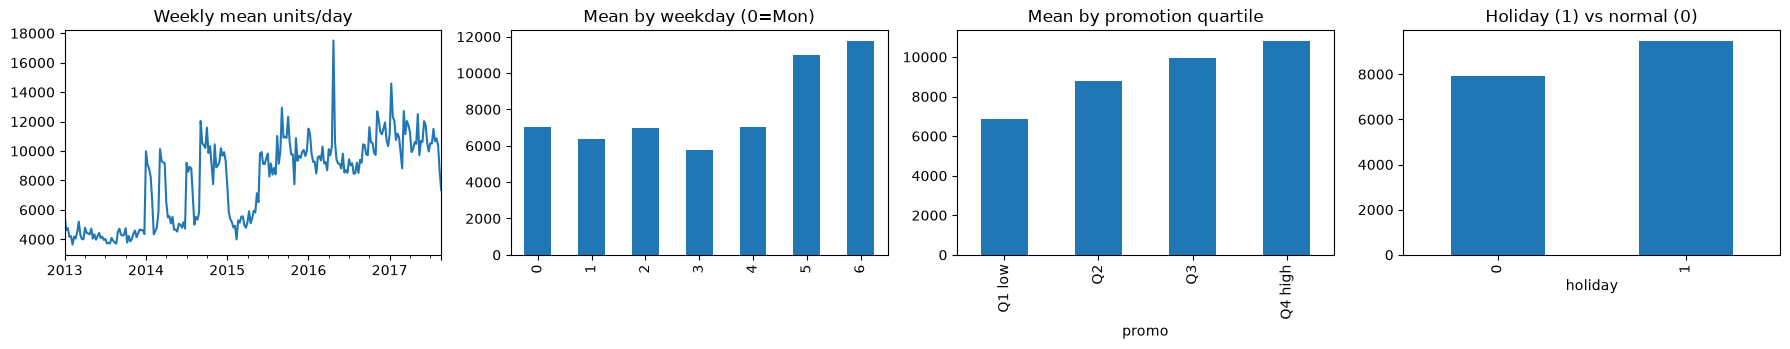

lag-7 autocorrelation 0.843 | corr(sales, promo) since 2014-04: 0.337


In [5]:
def frame(key):
    s = next(x for x in series if x['key'] == key)
    df = cal.loc[hist_dates].copy()
    df['sales'] = pd.Series(s['sales'], index=hist_dates, dtype=float)
    df['promo'] = pd.Series(s['onpromotion'][:len(hist_dates)], index=hist_dates)
    return df

d = frame(DEFAULT_KEY).dropna(subset=['sales'])
p = d[d.index >= TRAIN_START]
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
d.sales.resample('W').mean().plot(ax=ax[0], title='Weekly mean units/day'); ax[0].set_xlabel('')
d.groupby(d.index.dayofweek).sales.mean().plot.bar(ax=ax[1], title='Mean by weekday (0=Mon)')
p.groupby(pd.qcut(p.promo.rank(method='first'), 4, labels=['Q1 low','Q2','Q3','Q4 high']), observed=False).sales.mean().plot.bar(ax=ax[2], title='Mean by promotion quartile')
d.groupby('holiday').sales.mean().plot.bar(ax=ax[3], title='Holiday (1) vs normal (0)')
plt.tight_layout(); plt.show()
print('lag-7 autocorrelation', round(d.sales.autocorr(7), 3), '| corr(sales, promo) since 2014-04:', round(p.sales.corr(p.promo), 3))

## 5 · Export the subset for the dashboard

In [6]:
subset = {
    'schema': 'favorita-subset/v1',
    'source': 'Kaggle: Store Sales - Time Series Forecasting (Corporación Favorita). Derived subset; do not redistribute.',
    'generatedAt': dt.datetime.now().isoformat(timespec='seconds'),
    'startDate': START.date().isoformat(),
    'historyEnd': hist_end.date().isoformat(),
    'calendarEnd': CAL_END.date().isoformat(),
    'units': {'sales': 'units/day', 'leadTime': 'days'},
    'calendar': {
        'holiday': cal.holiday.tolist(), 'event': cal.event.tolist(), 'quake': cal.quake.tolist(),
        'oil': cal.oil.tolist(), 'name': [None if pd.isna(v) else v for v in cal.name],
    },
    'series': series,
}
path = OUT / 'favorita_subset.json'
path.write_text(json.dumps(subset, separators=(',', ':'), ensure_ascii=False), encoding='utf-8')
print(path, f'{path.stat().st_size/1024:.0f} KB', '| days', len(dates), '| history days', len(hist_dates))

C:\Users\levi7\Downloads\Lab 2\data\derived\favorita_subset.json 175 KB | days 1704 | history days 1688


## 6 · Reference implementation (mirrored exactly in `app/src/core`)

### 6.1 Feature set (all known in advance, so no leakage)
`dow_1..dow_6` (Monday is the base), yearly Fourier terms *k = 1..3* on the day index, `promo_log = log1p(onpromotion)`, `holiday`, `event`, `quake`, `payday` (15th or month-end), `oil` (previous day), `trend` (= day index / 365.25), and lags 7/14/28/364 plus `roll28_7` (mean of the 28 days ending 7 days ago).

For lag purposes, closed days are imputed with the value from the same weekday one week earlier.

In [7]:
FEATURES = ['dow_1','dow_2','dow_3','dow_4','dow_5','dow_6',
            'f_sin1','f_cos1','f_sin2','f_cos2','f_sin3','f_cos3',
            'promo_log','holiday','event','quake','payday','oil','trend',
            'lag7','lag14','lag28','lag364','roll28_7']

def impute(y):
    # Closed days (NaN) get the same-weekday value from one week earlier (0 if none exists)
    z = np.array(y, dtype=float).copy()
    for t in range(len(z)):
        if np.isnan(z[t]):
            z[t] = z[t-7] if t >= 7 else 0.0
    return z

DOW = np.array(dates.dayofweek)                                   # 0 = Monday
PAYDAY = ((dates.day == 15) | dates.is_month_end).astype(float)   # public-sector paydays in Ecuador

def feature_row(t, z, promo, C):
    # Features for day index t. z must hold (imputed or predicted) values for every day < t
    dow = DOW[t]
    r = [1.0 if dow == k else 0.0 for k in range(1, 7)]
    for k in (1, 2, 3):
        a = 2 * np.pi * k * t / 365.25
        r += [np.sin(a), np.cos(a)]
    payday = PAYDAY[t]
    r += [np.log1p(promo[t]), C['holiday'][t], C['event'][t], C['quake'][t], payday,
          C['oil'][max(t-1, 0)], t / 365.25,
          z[t-7], z[t-14], z[t-28], z[t-364], z[t-34:t-6].mean()]
    return r

C = {k: np.array(subset['calendar'][k], dtype=float) for k in ['holiday','event','quake','oil']}
S = {s['key']: (np.array([np.nan if v is None else v for v in s['sales']], dtype=float), np.array(s['onpromotion'], dtype=float)) for s in series}
TS = (TRAIN_START - START).days
print('TRAIN_START index', TS, '| history length', len(hist_dates))

TRAIN_START index 455 | history length 1688


### 6.2 Models

* **Seasonal naive:** ŷ(T+h) = y(T+h−7·⌈h/7⌉).
* **Holt-Winters:** additive, weekly season, damped trend. The parameters are fitted by Nelder–Mead on one-step-ahead SSE. Closed days are treated as missing (the state moves forward without an update).
* **Ridge:** standardised features, unpenalised intercept, closed-form solution. Multi-step forecasts are **recursive**: each prediction is fed back into the lags.

In [8]:
def seasonal_naive(z, T, H):
    # z = imputed series up to and including origin T (index). Returns forecasts for T+1..T+H
    return np.array([z[T + h - 7 * int(np.ceil(h / 7))] for h in range(1, H + 1)])

def hw_run(y, a, b, g, phi, m=7):
    # Additive damped Holt-Winters. y may contain NaN (closed). Returns final state and one-step SSE
    n = len(y); y0 = impute(y[:2*m])
    l = float(y0[:m].mean()); bt = float((y0[m:2*m].mean() - y0[:m].mean()) / m)
    s = (y0[:m] - l).tolist()
    y = np.asarray(y, dtype=float).tolist()          # plain floats: much faster in a Python loop
    sse = 0.0; cnt = 0
    for t in range(m, n):
        st = s[t - m]
        f = l + phi * bt + st
        if y[t] != y[t]:                             # NaN means a closed day

            l_new, b_new, s_new = l + phi * bt, phi * bt, st
        else:
            e = y[t] - f
            if t >= 2 * m: sse += e * e; cnt += 1
            l_new = a * (y[t] - st) + (1 - a) * (l + phi * bt)
            b_new = b * (l_new - l) + (1 - b) * phi * bt
            s_new = g * (y[t] - l - phi * bt) + (1 - g) * st
        l, bt = l_new, b_new; s.append(s_new)
    return l, bt, s, sse, cnt

def hw_forecast(state, H, phi, m=7):
    l, bt, s = state[0], state[1], state[2]
    n = len(s); out = []; damp = 0.0
    for h in range(1, H + 1):
        damp += phi ** h
        out.append(l + damp * bt + s[n - m + ((h - 1) % m)])
    return np.array(out)

from scipy.special import expit as sig            # numerically safe logistic
def hw_unpack(x):
    return sig(x[0]), sig(x[1]) * 0.2, sig(x[2]), 0.8 + 0.18 * sig(x[3])   # beta capped at 0.2, phi in (0.8, 0.98)
HW_X0 = np.array([-1.386294, -1.386294, -2.197225, 0.0])                     # alpha=0.2, beta=0.04, gamma=0.1, phi=0.89

def hw_fit(y):
    obj = lambda x: hw_run(y, *hw_unpack(x))[3]
    res = optimize.minimize(obj, HW_X0, method='Nelder-Mead', options=dict(maxiter=600, xatol=1e-4, fatol=1e-6))
    return hw_unpack(res.x), res.fun

def design(z, promo, T0, T1, y=None):
    X = np.array([feature_row(t, z, promo, C) for t in range(T0, T1 + 1)])
    return X

def ridge_fit(X, y, lam):
    mu = X.mean(0); sd = X.std(0); sd[sd < 1e-12] = 1.0
    Xs = (X - mu) / sd; ym = y.mean()
    beta = np.linalg.solve(Xs.T @ Xs + lam * np.eye(X.shape[1]), Xs.T @ (y - ym))
    return dict(mu=mu, sd=sd, beta=beta, b0=ym)

def ridge_predict(m, X):
    return m['b0'] + ((X - m['mu']) / m['sd']) @ m['beta']

_XCACHE = {}
def ridge_train(y, promo, T, lam):
    # Train on open days in [TS, T]. The design matrix is cached per (series, origin) because λ does not change it
    ck = (id(y), T)
    if ck not in _XCACHE:
        z = impute(y[:T + 1])
        idx = np.array([t for t in range(TS, T + 1) if not np.isnan(y[t])])
        _XCACHE[ck] = (np.array([feature_row(t, z, promo, C) for t in idx]), y[idx])
    X, yy = _XCACHE[ck]
    return ridge_fit(X, yy, lam)

def ridge_forecast(m, y, promo, T, H):
    z = list(impute(y[:T + 1]))
    out = []
    for h in range(1, H + 1):
        t = T + h
        p = max(0.0, float(ridge_predict(m, np.array([feature_row(t, np.array(z + [0.0]), promo, C)]))[0]))
        out.append(p); z.append(p)
    return np.array(out)

### 6.3 Metrics and backtest protocol

* **Metrics:** MAE, RMSE, WAPE = Σ|e| / Σy, **MASE** = MAE ÷ in-sample MAE of the weekly seasonal naive, and **Bias** = mean(ŷ − y), where a positive value means over-forecasting.
* **Protocol:** origins every 14 days back from the end of the history. The **6 test origins** (k = 1..6) produce the leaderboard. The **12 calibration origins** (k = 7..18) are used for choosing λ and for the conformal residuals. H = 14 days, and models are refitted at every origin.

In [9]:
H = 14
END = len(hist_dates) - 1
TEST_ORIGINS = [END - 14 * k for k in range(6, 0, -1)]
CAL_ORIGINS = [END - 14 * k for k in range(18, 6, -1)]
iso = lambda t: (START + pd.Timedelta(days=int(t))).date().isoformat()
print('test origins', [iso(t) for t in TEST_ORIGINS]); print('calibration origins', iso(CAL_ORIGINS[0]), '...', iso(CAL_ORIGINS[-1]))

def metrics(y, f, scale):
    m = ~np.isnan(y); y, f = y[m], f[m]; e = f - y
    return dict(mae=float(np.abs(e).mean()), rmse=float(np.sqrt((e ** 2).mean())), wape=float(np.abs(e).sum() / y.sum() * 100),
                mase=float(np.abs(e).mean() / scale), bias=float(e.mean()), n=int(m.sum()))

def snaive_scale(y, T):
    z = y[TS:T + 1]; d = np.abs(z[7:] - z[:-7]); return float(np.nanmean(d))

LAMBDAS = [0.1, 1, 10, 100, 1000]
def backtest(key):
    y, promo = S[key]
    # λ by mean MAE over the calibration origins
    lam_scores = {}
    for lam in LAMBDAS:
        errs = [np.nanmean(np.abs(ridge_forecast(ridge_train(y, promo, T, lam), y, promo, T, H) - y[T+1:T+H+1])) for T in CAL_ORIGINS]
        lam_scores[lam] = float(np.mean(errs))
    lam = min(lam_scores, key=lam_scores.get)
    res = {'snaive': [], 'holtwinters': [], 'ridge': []}; actual = []; hw_params = []
    for T in CAL_ORIGINS + TEST_ORIGINS:
        z = impute(y[:T + 1])
        f_sn = seasonal_naive(z, T, H)
        (a, b, g, phi), _ = hw_fit(y[TS:T + 1]); hw_params.append([a, b, g, phi])
        f_hw = hw_forecast(hw_run(y[TS:T + 1], a, b, g, phi), H, phi)
        f_rg = ridge_forecast(ridge_train(y, promo, T, lam), y, promo, T, H)
        res['snaive'].append(f_sn); res['holtwinters'].append(f_hw); res['ridge'].append(f_rg); actual.append(y[T + 1:T + H + 1])
    nC = len(CAL_ORIGINS)
    scale = snaive_scale(y, TEST_ORIGINS[0])
    A = np.concatenate(actual[nC:])
    board = {k: metrics(A, np.concatenate(v[nC:]), scale) for k, v in res.items()}
    return dict(lam=lam, lam_scores=lam_scores, board=board, res=res, actual=actual, hw_params=hw_params, scale=scale)

bt = backtest(DEFAULT_KEY)
print('ridge λ =', bt['lam'], {k: round(v, 1) for k, v in bt['lam_scores'].items()})
pd.DataFrame(bt['board']).T.round(2)

test origins ['2017-05-23', '2017-06-06', '2017-06-20', '2017-07-04', '2017-07-18', '2017-08-01']
calibration origins 2016-12-06 ... 2017-05-09


ridge λ = 100 {0.1: 1528.0, 1: 1527.4, 10: 1522.8, 100: 1519.1, 1000: 1625.1}


,mae,rmse,wape,mase,bias,n
snaive,1823.65,2463.47,17.14,1.22,717.25,84.0
holtwinters,1609.13,2174.24,15.12,1.08,794.60,84.0
ridge,1458.43,1906.63,13.71,0.98,473.69,84.0


### 6.4 Split-conformal 80% / 95% intervals

The calibration residuals (y − ŷ) from the 12 calibration origins are pooled across horizons (168 residuals per model). The interval is ŷ + [q_lo, q_hi], and its **coverage is measured on the 6 untouched test origins**.

In [10]:
def conformal(bt, model, levels=(0.8, 0.95)):
    nC = len(CAL_ORIGINS)
    r = np.concatenate([a - f for a, f in zip(bt['actual'][:nC], bt['res'][model][:nC])]); r = r[~np.isnan(r)]
    A = np.concatenate(bt['actual'][nC:]); F = np.concatenate(bt['res'][model][nC:]); m = ~np.isnan(A)
    out = {}
    for lv in levels:
        lo, hi = np.quantile(r, [(1 - lv) / 2, 1 - (1 - lv) / 2], method='linear')
        cov = float(((A[m] >= F[m] + lo) & (A[m] <= F[m] + hi)).mean())
        out[str(lv)] = dict(lo=float(lo), hi=float(hi), coverage=cov)
    return out, float(np.std(r, ddof=1))

for mdl in ['snaive', 'holtwinters', 'ridge']:
    ci, sd = conformal(bt, mdl)
    print(f"{mdl:12s} residual sd={sd:8.1f}  80%: [{ci['0.8']['lo']:8.1f},{ci['0.8']['hi']:8.1f}] coverage={ci['0.8']['coverage']:.2f}   95%: coverage={ci['0.95']['coverage']:.2f}")

snaive       residual sd=  2897.2  80%: [ -3006.5,  2921.5] coverage=0.81   95%: coverage=0.96
holtwinters  residual sd=  2371.2  80%: [ -3232.1,  2252.7] coverage=0.87   95%: coverage=0.94
ridge        residual sd=  2184.6  80%: [ -1715.9,  3525.1] coverage=0.75   95%: coverage=0.95


### 6.5 Leaderboard across all 9 series (reference results for the dashboard)

In [11]:
rows = []
all_bt = {}
for key in S:
    b = backtest(key); all_bt[key] = b
    for mdl, m in b['board'].items():
        rows.append(dict(series=key, model=mdl, **{k: round(v, 3) for k, v in m.items()}, lam=b['lam']))
board = pd.DataFrame(rows)
print(board.pivot(index='series', columns='model', values='wape').round(1))

model         holtwinters  ridge  snaive
series                                  
3|BEVERAGES          12.5   11.5    14.8
3|CLEANING           16.9   11.3    19.1
3|GROCERY I          10.7    7.5    13.9
44|BEVERAGES         15.1   13.7    17.1
44|CLEANING          17.5   13.2    19.2
44|GROCERY I         12.4   10.2    14.0
45|BEVERAGES         13.9   11.7    15.6
45|CLEANING          21.6   11.2    21.5
45|GROCERY I         14.2   10.1    16.8


### 6.6 Safety stock: slide formula and Monte Carlo cross-check

SS = Z·√(σ_D²·L + D̄²·σ_L²), and ROP = D̄·L + SS (daily units throughout).

Hand calculation for D̄ = 100 u/d, σ_D = 20 u/d, L = 5 d, σ_L = 1.5 d, SL = 95%:
√(2,000 + 22,500) = 156.52, so SS = 1.6449 × 156.52 = **257.46**.

In [12]:
def safety_stock(z, sd_d, d_bar, L, sd_L):
    return z * np.sqrt(sd_d ** 2 * L + d_bar ** 2 * sd_L ** 2)
Z95 = stats.norm.ppf(0.95)
ss = safety_stock(Z95, 20, 100, 5, 1.5)
print(f'Z={Z95:.6f}  SS={ss:.4f}  ROP={100*5+ss:.4f}')
assert abs(ss - 257.46) < 0.01

rng = np.random.default_rng(7); N = 400_000
k, th = (5 / 1.5) ** 2, 1.5 ** 2 / 5
Ls = rng.gamma(k, th, N)
ddlt = rng.normal(100 * Ls, 20 * np.sqrt(Ls))
mc = dict(mean=float(ddlt.mean()), sd=float(ddlt.std()), p_stockout_at_formula_rop=float((ddlt > 500 + ss).mean()),
          q95=float(np.quantile(ddlt, 0.95)))
print({k: round(v, 4) for k, v in mc.items()}, '| theory sd', round(np.sqrt(20**2*5 + 100**2*1.5**2), 3))

Z=1.644854  SS=257.4603  ROP=757.4603
{'mean': 499.671, 'sd': 156.3253, 'p_stockout_at_formula_rop': 0.0628, 'q95': 780.3166} | theory sd 156.525


## 7 · Golden fixtures for the TypeScript tests

These are written to `data/derived/fixtures/`, which is git-ignored because they are derived from the data. The TS tests that need them are skipped when the files are absent. Data-free tests (formula, Z values, samplers) always run.

In [13]:
y, promo = S[DEFAULT_KEY]
T = TEST_ORIGINS[0]
z = impute(y[:T + 1])
fx = {}
fx['meta'] = dict(key=DEFAULT_KEY, trainStart=TS, origin=T, originDate=iso(T), H=H, testOrigins=TEST_ORIGINS, calOrigins=CAL_ORIGINS, features=FEATURES)
fx['features'] = {str(t): feature_row(t, z, promo, C) for t in [T - 400, T - 1, T]}
fx['snaive'] = seasonal_naive(z, T, H).tolist()
HWP = (0.3, 0.02, 0.15, 0.9)
fx['hwFixed'] = dict(params=HWP, forecast=hw_forecast(hw_run(y[TS:T + 1], *HWP), H, 0.9).tolist(), sse=hw_run(y[TS:T + 1], *HWP)[3])
(pa, pb, pg, pphi), sse = hw_fit(y[TS:T + 1])
fx['hwFit'] = dict(params=[pa, pb, pg, pphi], sse=float(sse))
m10 = ridge_train(y, promo, T, 10.0)
fx['ridgeFixed'] = dict(lam=10.0, b0=float(m10['b0']), beta=m10['beta'].tolist(), mu=m10['mu'].tolist(), sd=m10['sd'].tolist(),
                        forecast=ridge_forecast(m10, y, promo, T, H).tolist())
fx['backtest'] = {k: dict(lam=b['lam'], board=b['board'], scale=b['scale']) for k, b in all_bt.items()}
fx['conformal'] = {mdl: conformal(bt, mdl)[0] for mdl in ['snaive', 'holtwinters', 'ridge']}
fx['safetyStock'] = dict(inputs=dict(z=Z95, sd_d=20, d_bar=100, L=5, sd_L=1.5), ss=float(ss), rop=float(500 + ss), mc=mc,
                         z_values={str(p): float(stats.norm.ppf(p)) for p in [0.5, 0.8, 0.9, 0.95, 0.975, 0.99, 0.999]})
(FIX / 'reference.json').write_text(json.dumps(fx, indent=1), encoding='utf-8')
print('fixtures written:', list(fx))

fixtures written: ['meta', 'features', 'snaive', 'hwFixed', 'hwFit', 'ridgeFixed', 'backtest', 'conformal', 'safetyStock']


## 8 · Summary

* The cleaned subset exports **9 series** covering 1,688 days of history (2013-01-01 to 2017-08-15), plus 16 days of known future promotions from `test.csv`.
* The holdout leaderboard above (Holt-Winters and Ridge against the seasonal-naive benchmark) is the **reference result** that the dashboard's TypeScript models must reproduce.
* The LSTM is trained and evaluated in TypeScript (TF.js) under the same protocol. Its pre-training cut-off is the first calibration origin, so its backtest is leak-free.
* The safety-stock formula matches the hand calculation (257.46). Monte Carlo with skewed gamma lead times gives P(stockout) above the nominal 5% at the formula's ROP, which is why the dashboard reports both.